# Proyek Analisis Data: E-Commerce Public Dataset (Olist)

- **Nama:** FI AMALIA UTAMI
- **Email:** fiamaliautami12@gmail.com
- **ID Dicoding:** DS466B6X1880

## Menentukan Pertanyaan Bisnis

Periode analisis: **Januari 2017 - Agustus 2018** (periode dengan data transaksi yang lengkap; tahun 2016 dan akhir 2018 sangat sedikit transaksinya, dibuktikan pada tahap Assessing Data).

1. **Kategori produk apa saja yang menghasilkan revenue tertinggi (top 10) pada periode Januari 2017 - Agustus 2018, dan berapa persen kontribusi 5 kategori teratas terhadap total revenue?**
   - *Specific:* fokus pada kategori produk. *Measurable:* revenue (R$) dan persentase kontribusi. *Action-oriented:* menentukan kategori prioritas untuk stok dan promosi. *Relevant:* revenue adalah tujuan utama e-commerce. *Time-bound:* Jan 2017 - Agu 2018.
2. **Negara bagian (state) mana yang memiliki jumlah pelanggan unik terbanyak dan mana yang memiliki rata-rata waktu pengiriman paling lama pada periode Januari 2017 - Agustus 2018?**
   - *Specific:* level negara bagian pelanggan. *Measurable:* jumlah pelanggan unik dan rata-rata waktu pengiriman (hari). *Action-oriented:* menentukan wilayah prioritas untuk perbaikan logistik dan pembukaan pusat distribusi. *Relevant:* kecepatan pengiriman memengaruhi kepuasan pelanggan. *Time-bound:* Jan 2017 - Agu 2018.
3. **Bagaimana segmentasi pelanggan unik berdasarkan RFM (Recency, Frequency, Monetary) pada periode Januari 2017 - Agustus 2018, dan segmen mana yang menyumbang revenue terbesar?**
   - *Specific:* segmentasi pelanggan unik. *Measurable:* jumlah pelanggan dan persentase revenue per segmen. *Action-oriented:* menentukan strategi retensi dan promosi tiap segmen. *Relevant:* retensi pelanggan menentukan pertumbuhan jangka panjang. *Time-bound:* Jan 2017 - Agu 2018.

## Menyiapkan semua library yang dibutuhkan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Data Wrangling

### Gathering Data

Dari 9 berkas dataset, hanya 6 yang dibutuhkan untuk menjawab ketiga pertanyaan bisnis:

| Berkas | Kegunaan |
|---|---|
| `orders_dataset.csv` | status pesanan, tanggal pembelian, tanggal pesanan sampai |
| `order_items_dataset.csv` | produk dan harga (dasar perhitungan revenue) |
| `customers_dataset.csv` | identitas unik pelanggan, kode pos, negara bagian |
| `products_dataset.csv` | kategori produk |
| `product_category_name_translation.csv` | terjemahan nama kategori ke bahasa Inggris |
| `geolocation_dataset.csv` | koordinat latitude/longitude berdasarkan kode pos |

In [2]:
customers_df = pd.read_csv("data/customers_dataset.csv")
orders_df = pd.read_csv("data/orders_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")
category_translation_df = pd.read_csv("data/product_category_name_translation.csv")
geolocation_df = pd.read_csv("data/geolocation_dataset.csv")

datasets = {
    "customers": customers_df,
    "orders": orders_df,
    "order_items": order_items_df,
    "products": products_df,
    "category_translation": category_translation_df,
    "geolocation": geolocation_df,
}
for name, df in datasets.items():
    print(f"=== {name} | {df.shape[0]:,} baris, {df.shape[1]} kolom ===")
    display(df.head(3))

=== customers | 99,441 baris, 5 kolom ===


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


=== orders | 99,441 baris, 8 kolom ===


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


=== order_items | 112,650 baris, 7 kolom ===


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87


... (2 outputs left out)

=== category_translation | 71 baris, 2 kolom ===


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


=== geolocation | 1,000,163 baris, 5 kolom ===


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP


**Insight (Gathering Data):**

Data berhasil dimuat dari 6 tabel. Tabel geolocation paling besar dengan 1.000.163 baris dan 5 kolom, sedangkan tabel products berisi 32.951 produk dengan 9 kolom. Tabel category_translation hanya berisi 71 baris karena fungsinya menerjemahkan nama kategori. Tabel customers berisi 99,441 baris, orders 99,441 baris, dan order_items 112,650 baris.

Tabel-tabel ini dihubungkan melalui beberapa kunci: order_id (orders dan order_items), customer_id (orders dan customers), product_id (order_items dan products), product_category_name (products dan category_translation), serta kode pos (customers dan geolocation).

Ada dua hal yang perlu ditangani di tahap berikutnya. Pertama, nama kategori produk masih berbahasa Portugis (misalnya beleza_saude, esporte_lazer), sehingga perlu diterjemahkan ke bahasa Inggris. Kedua, tabel geolocation memuat banyak baris dengan kode pos dan koordinat yang sama (misalnya kode pos 1046 muncul berulang), yang mengindikasikan adanya data duplikat.

### Assessing Data

Pengecekan kualitas data: missing value, duplicate data, invalid value, inconsistent value, inaccurate value, dan outlier.

In [3]:
# Ringkasan umum: jumlah baris, missing value, dan data duplikat tiap tabel
summary = pd.DataFrame({
    "jumlah_baris": {n: d.shape[0] for n, d in datasets.items()},
    "total_missing_value": {n: int(d.isna().sum().sum()) for n, d in datasets.items()},
    "baris_duplikat": {n: int(d.duplicated().sum()) for n, d in datasets.items()},
})
summary

,jumlah_baris,total_missing_value,baris_duplikat
customers,99441,0,0
orders,99441,4908,0
order_items,112650,0,0
products,32951,2448,0
category_translation,71,0,0
geolocation,1000163,0,261831


In [4]:
# Missing value per kolom (hanya kolom yang memiliki missing value)
for name in ["orders", "products"]:
    miss = datasets[name].isna().sum()
    print(f"--- {name} ---")
    print(miss[miss > 0], "\n")

--- orders ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

--- products ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64 



In [5]:
# Inconsistent value: status pesanan beragam, padahal analisis revenue memerlukan pesanan yang benar-benar selesai
orders_df["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [6]:
# Inconsistent value: tipe data kolom tanggal masih object (string)
orders_df.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [7]:
# Invalid value dan cakupan periode data
tmp = orders_df.copy()
for col in ["order_purchase_timestamp", "order_delivered_customer_date"]:
    tmp[col] = pd.to_datetime(tmp[col])

invalid_delivery = (tmp["order_delivered_customer_date"] < tmp["order_purchase_timestamp"]).sum()
print("Pesanan tiba SEBELUM tanggal pembelian (invalid):", invalid_delivery)
print("\nJumlah pesanan per bulan:")
print(tmp["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index())

Pesanan tiba SEBELUM tanggal pembelian (invalid): 0

Jumlah pesanan per bulan:
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64


In [8]:
# Duplicate data dan inaccurate value pada geolocation
print("Baris duplikat geolocation:", geolocation_df.duplicated().sum())

# Koordinat di luar wilayah Brasil dianggap tidak akurat
outside_brazil = (
    ~geolocation_df["geolocation_lat"].between(-34, 6)
    | ~geolocation_df["geolocation_lng"].between(-74, -34)
)
print("Koordinat di luar wilayah Brasil:", outside_brazil.sum())

Baris duplikat geolocation: 261831
Koordinat di luar wilayah Brasil: 42


In [9]:
# Outlier pada harga produk (metode IQR)
q1, q3 = order_items_df["price"].quantile([0.25, 0.75])
upper_bound = q3 + 1.5 * (q3 - q1)
n_outlier = (order_items_df["price"] > upper_bound).sum()
print(f"Batas atas outlier harga: R$ {upper_bound:,.2f}")
print(f"Jumlah item di atas batas: {n_outlier:,} ({n_outlier / len(order_items_df):.1%})")
order_items_df["price"].describe()

Batas atas outlier harga: R$ 277.40
Jumlah item di atas batas: 8,427 (7.5%)


count   112,650.00
mean        120.65
std         183.63
min           0.85
25%          39.90
50%          74.99
75%         134.90
max       6,735.00
Name: price, dtype: float64

**Insight (Assessing Data) dan rencana Cleaning:**

| Masalah | Tabel | Tindakan pada Cleaning |
|---|---|---|
| Missing value (tanggal pesanan sampai, kategori produk) | orders, products | Hapus pesanan tanpa tanggal sampai; isi kategori kosong dengan `unknown` |
| Inconsistent value: status pesanan beragam | orders | Hanya gunakan pesanan berstatus `delivered` |
| Inconsistent value: tipe data tanggal berupa string; kategori berbahasa Portugis | orders, products | Ubah ke datetime; terjemahkan kategori dengan tabel translasi |
| Invalid value: tanggal tiba lebih awal dari tanggal beli (jika ada) | orders | Hapus baris tersebut |
| Duplicate data | geolocation | Hapus baris duplikat |
| Inaccurate value: koordinat di luar Brasil | geolocation | Hapus baris di luar batas koordinat Brasil |
| Cakupan periode tidak merata (2016 dan akhir 2018 sangat sedikit) | orders | Batasi analisis pada Jan 2017 - Agu 2018 |
| Outlier harga | order_items | **Dipertahankan**, karena produk bernilai tinggi (mis. perabot/elektronik) adalah transaksi yang sah dan memengaruhi revenue |

Setelah dicek, data ini belum sepenuhnya rapi dan ada beberapa masalah yang harus dibereskan dulu sebelum dianalisis.

- Data kosong: di tabel orders, kolom tanggal pesanan sampai kosong di 2.965 baris, dan kebanyakan karena pesanannya memang belum selesai. Di tabel products, ada 610 produk tanpa kategori. Pesanan tanpa tanggal sampai akan dibuang, sedangkan produk tanpa kategori diberi label unknown.
- Status pesanan campur-campur: dari 99.441 pesanan, 96.478 (sekitar 97%) berstatus delivered. Sisanya masih dikirim, dibatalkan, tidak tersedia, atau masih diproses. Karena revenue dihitung dari pesanan yang benar-benar selesai, hanya pesanan delivered yang dipakai.
- Format data tidak seragam: kolom tanggal masih berupa teks sehingga perlu diubah ke format tanggal, dan nama kategori produk masih berbahasa Portugis sehingga perlu diterjemahkan ke bahasa Inggris.
- Data kembar dan koordinat salah: tabel geolocation punya 261.831 baris duplikat (sekitar seperempat dari total 1.000.163 baris) dan 42 titik koordinat yang letaknya di luar Brasil. Keduanya dihapus supaya peta tidak melenceng.
- Tanggal tidak masuk akal: sudah dicek, tidak ada pesanan yang tanggal tibanya lebih awal dari tanggal beli, jadi bagian ini aman. Pengecekannya tetap dimasukkan ke tahap cleaning sebagai pengaman.
- Periode data tidak merata: transaksi tahun 2016 hanya ada 329 pesanan (Sep, Okt, dan Des saja), dan September-Oktober 2018 hanya 20 pesanan, jauh di bawah 6.000-7.000 pesanan per bulan pada pertengahan 2018. Karena itu analisis dibatasi pada Januari 2017 sampai Agustus 2018 supaya perbandingannya adil.
- Harga yang sangat tinggi: harga produk berkisar dari R$ 0,85 sampai R$ 6.735. Harga tengah (median) R$ 74,99, lebih rendah dari rata-rata R$ 120,65, tanda bahwa ada barang mahal yang menarik rata-rata ke atas. Ada 8.427 item (7,5%) di atas batas R$ 277,40. Harga setinggi itu tetap dipertahankan karena wajar untuk barang mahal seperti furnitur atau elektronik, dan tetap berpengaruh pada revenue.


### Cleaning Data

**1. Tabel `orders`:** ubah tipe data tanggal, ambil pesanan `delivered`, hapus tanggal tiba yang kosong atau invalid, batasi periode, lalu hitung waktu pengiriman (hari).

In [10]:
datetime_cols = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
for col in datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

n_awal = len(orders_df)
orders_clean = orders_df[orders_df["order_status"] == "delivered"].copy()
orders_clean = orders_clean.dropna(subset=["order_delivered_customer_date"])
orders_clean = orders_clean[
    orders_clean["order_delivered_customer_date"] >= orders_clean["order_purchase_timestamp"]
]
orders_clean = orders_clean[
    (orders_clean["order_purchase_timestamp"] >= "2017-01-01")
    & (orders_clean["order_purchase_timestamp"] < "2018-09-01")
]
orders_clean["delivery_time_days"] = (
    orders_clean["order_delivered_customer_date"] - orders_clean["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print(f"Pesanan sebelum cleaning: {n_awal:,} | sesudah cleaning: {len(orders_clean):,}")
orders_clean[["order_id", "order_purchase_timestamp", "delivery_time_days"]].head()

Pesanan sebelum cleaning: 99,441 | sesudah cleaning: 96,203


,order_id,order_purchase_timestamp,delivery_time_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,8.44
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,13.78
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,9.39
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,13.21
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2.87


**2. Tabel `products`:** terjemahkan kategori ke bahasa Inggris dan tangani kategori kosong.

In [11]:
products_clean = products_df.merge(category_translation_df, on="product_category_name", how="left")
# kategori tanpa terjemahan memakai nama aslinya, kategori kosong menjadi "unknown"
products_clean["product_category_name_english"] = (
    products_clean["product_category_name_english"]
    .fillna(products_clean["product_category_name"])
    .fillna("unknown")
)
products_clean = products_clean[["product_id", "product_category_name_english"]]
products_clean["product_category_name_english"].value_counts().head()

product_category_name_english
bed_bath_table     3029
sports_leisure     2867
furniture_decor    2657
health_beauty      2444
housewares         2335
Name: count, dtype: int64

**3. Tabel `geolocation`:** hapus duplikat, hapus koordinat di luar Brasil, lalu ambil titik tengah (rata-rata) koordinat per kode pos.

In [12]:
n_geo_awal = len(geolocation_df)
geo_clean = geolocation_df.drop_duplicates()
in_brazil = (
    geo_clean["geolocation_lat"].between(-34, 6)
    & geo_clean["geolocation_lng"].between(-74, -34)
)
geo_clean = geo_clean[in_brazil]

geo_zip = (
    geo_clean.groupby("geolocation_zip_code_prefix")
    .agg(geolocation_lat=("geolocation_lat", "mean"), geolocation_lng=("geolocation_lng", "mean"))
    .reset_index()
)
print(f"Baris geolocation: {n_geo_awal:,} -> {len(geo_clean):,} | kode pos unik: {len(geo_zip):,}")

Baris geolocation: 1,000,163 -> 738,299 | kode pos unik: 19,010


**4. Menggabungkan semua tabel menjadi satu dataset utama (`main_data.csv`)** yang akan dipakai juga oleh dashboard.

Revenue didefinisikan sebagai total `price` item pada pesanan berstatus `delivered` (tidak termasuk ongkos kirim).

In [13]:
main_df = (
    order_items_df[["order_id", "product_id", "price"]]
    .merge(
        orders_clean[["order_id", "customer_id", "order_purchase_timestamp", "delivery_time_days"]],
        on="order_id", how="inner",
    )
    .merge(
        customers_df[["customer_id", "customer_unique_id", "customer_zip_code_prefix", "customer_state"]],
        on="customer_id", how="left",
    )
    .merge(products_clean, on="product_id", how="left")
    .merge(geo_zip, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left")
)
main_df = main_df[[
    "order_id", "customer_unique_id", "order_purchase_timestamp",
    "product_category_name_english", "price", "customer_state",
    "delivery_time_days", "geolocation_lat", "geolocation_lng",
]]
main_df = main_df.assign(
    product_category_name_english=main_df["product_category_name_english"].fillna("unknown")
)

os.makedirs("dashboard", exist_ok=True)
main_df.to_csv("dashboard/main_data.csv", index=False)

print("Ukuran main_df:", main_df.shape)
print("Missing value tersisa:\n", main_df.isna().sum())
main_df.head()

Ukuran main_df: (109872, 9)
Missing value tersisa:
 order_id                           0
customer_unique_id                 0
order_purchase_timestamp           0
product_category_name_english      0
price                              0
customer_state                     0
delivery_time_days                 0
geolocation_lat                  289
geolocation_lng                  289
dtype: int64


,order_id,customer_unique_id,order_purchase_timestamp,product_category_name_english,price,customer_state,delivery_time_days,geolocation_lat,geolocation_lng
0,00010242fe8c5a6d1ba2dd792cb16214,871766c5855e863f6eccc05f988b23cb,2017-09-13 08:59:02,cool_stuff,58.90,RJ,7.61,-21.76,-41.31
1,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,2017-04-26 10:53:06,pet_shop,239.90,SP,16.22,-20.22,-50.90
2,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,2018-01-14 14:33:31,furniture_decor,199.00,MG,7.95,-19.87,-44.59
3,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,2018-08-08 10:00:35,perfumery,12.99,SP,6.15,-23.11,-46.59
4,00042b26cf59d7ce69dfabb4e55b4fd9,64b576fb70d441e8f1b2d7d446e483c5,2017-02-04 13:57:51,garden_tools,199.90,SP,25.11,-23.24,-46.83


**Insight (Cleaning Data):**

Setelah proses pembersihan, data siap dipakai untuk analisis.

- Pesanan: dari 99.441 pesanan awal, tersisa 96.203 pesanan (sekitar 96,7%). Sebanyak 3.238 pesanan dibuang karena statusnya belum selesai (dibatalkan, masih dikirim, dan sebagainya), tanggal tibanya kosong, atau terjadi di luar periode Januari 2017 sampai Agustus 2018. Setiap pesanan yang tersisa juga sudah punya kolom waktu pengiriman dalam hitungan hari.
- Kategori produk: nama kategori sudah berbahasa Inggris, dan produk yang tidak punya kategori diberi label unknown. Contoh kategori yang paling banyak jumlah produknya adalah bed_bath_table, sports_leisure, dan furniture_decor.
- Geolocation: jumlah barisnya turun dari 1.000.163 menjadi 738.299 setelah 261.864 baris dibuang (sekitar 26%), terdiri dari baris duplikat dan titik koordinat di luar Brasil. Titik-titiknya lalu dirata-rata per kode pos, sehingga menjadi 19.010 kode pos unik dengan satu koordinat masing-masing.
- Dataset utama: hasil penggabungan semua tabel berisi 109.872 baris dan 9 kolom, disimpan sebagai main_data.csv untuk dashboard. Semua kolom sudah lengkap, kecuali koordinat (geolocation_lat dan geolocation_lng) yang kosong di 289 baris (sekitar 0,26%). Kosongnya karena kode pos pelanggan tersebut tidak ditemukan di tabel geolocation. Jumlahnya sangat kecil, jadi dibiarkan saja. Baris ini tetap dipakai untuk analisis revenue dan kategori, dan hanya dilewati saat menghitung titik koordinat di peta.

## Exploratory Data Analysis (EDA)

In [14]:
period_text = (
    f"{main_df['order_purchase_timestamp'].min().date()} s.d. "
    f"{main_df['order_purchase_timestamp'].max().date()}"
)
total_revenue = main_df["price"].sum()
print("Periode data   :", period_text)
print(f"Total revenue  : R$ {total_revenue:,.2f}")
print(f"Total pesanan  : {main_df['order_id'].nunique():,}")
print(f"Pelanggan unik : {main_df['customer_unique_id'].nunique():,}")

Periode data   : 2017-01-05 s.d. 2018-08-29
Total revenue  : R$ 13,179,777.95
Total pesanan  : 96,203
Pelanggan unik : 93,096


### Pertanyaan 1: Revenue per kategori produk

In [15]:
category_revenue = (
    main_df.groupby("product_category_name_english")
    .agg(revenue=("price", "sum"), orders=("order_id", "nunique"))
    .reset_index()
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)
category_revenue["share_pct"] = category_revenue["revenue"] / category_revenue["revenue"].sum() * 100

top5_share = category_revenue.head(5)["share_pct"].sum()
print(f"Kontribusi 5 kategori teratas terhadap total revenue: {top5_share:.1f}%")
category_revenue.head(10)

Kontribusi 5 kategori teratas terhadap total revenue: 39.9%


,product_category_name_english,revenue,orders,share_pct
0,health_beauty,"1,229,557.50",8610,9.33
1,watches_gifts,"1,163,187.91",5489,8.83
2,bed_bath_table,"1,022,955.77",9267,7.76
3,sports_leisure,"952,661.40",7512,7.23
4,computers_accessories,"887,944.60",6517,6.74
5,furniture_decor,"706,237.17",6258,5.36
6,housewares,"614,341.62",5734,4.66
7,cool_stuff,"609,158.00",3552,4.62
8,auto,"577,721.09",3801,4.38
9,garden_tools,"469,135.40",3443,3.56


### Pertanyaan 2: Pelanggan dan waktu pengiriman per negara bagian

In [16]:
# Level pesanan (satu baris per order) agar waktu pengiriman tidak terhitung ganda
order_level = main_df.drop_duplicates("order_id")

state_summary = (
    order_level.groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("order_id", "nunique"),
        avg_delivery_days=("delivery_time_days", "mean"),
        lat=("geolocation_lat", "mean"),
        lng=("geolocation_lng", "mean"),
    )
    .reset_index()
)
state_revenue = main_df.groupby("customer_state")["price"].sum().rename("revenue").reset_index()
state_summary = (
    state_summary.merge(state_revenue, on="customer_state")
    .sort_values("customers", ascending=False)
    .reset_index(drop=True)
)

print("Top 5 negara bagian berdasarkan jumlah pelanggan unik:")
display(state_summary.head(5)[["customer_state", "customers", "orders", "revenue", "avg_delivery_days"]])

# hanya state dengan minimal 100 pesanan agar rata-rata waktu pengiriman cukup representatif
slowest_states = (
    state_summary[state_summary["orders"] >= 100]
    .sort_values("avg_delivery_days", ascending=False)
)
print("5 negara bagian dengan pengiriman terlama (minimal 100 pesanan):")
slowest_states.head(5)[["customer_state", "orders", "avg_delivery_days"]]

Top 5 negara bagian berdasarkan jumlah pelanggan unik:


,customer_state,customers,orders,revenue,avg_delivery_days
0,SP,39058,40399,"5,054,516.95",8.74
1,RJ,11879,12310,"1,751,433.85",15.30
2,MG,10969,11319,"1,548,206.88",11.98
3,RS,5150,5327,"726,194.92",15.29
4,PR,4750,4903,"664,048.00",11.97


5 negara bagian dengan pengiriman terlama (minimal 100 pesanan):


,customer_state,orders,avg_delivery_days
23,AM,145,26.43
19,AL,396,24.52
12,PA,942,23.76
14,MA,713,21.54
20,SE,332,21.44


### Pertanyaan 3: Segmentasi pelanggan dengan RFM Analysis (Analisis Lanjutan)

**Tujuan analisis lanjutan:** RFM Analysis mengelompokkan pelanggan berdasarkan perilaku belanjanya, yaitu *Recency* (berapa hari sejak pembelian terakhir), *Frequency* (jumlah pesanan), dan *Monetary* (total pengeluaran). Hasilnya dipakai untuk menentukan strategi promosi dan retensi yang berbeda untuk tiap segmen.

**Teknik pengelompokan (tanpa machine learning):** *binning* dengan kuartil (`qcut`) untuk skor Recency dan Monetary, serta *manual grouping* berbasis aturan bisnis untuk memberi nama segmen. Frequency tidak dibagi kuartil karena mayoritas pelanggan hanya berbelanja sekali, sehingga dibedakan menjadi pelanggan sekali beli dan pelanggan berulang.

| Segmen | Aturan |
|---|---|
| Repeat Customer | frequency >= 2 |
| Recent High Value | frequency = 1, skor R >= 3, skor M >= 3 |
| Recent Low Value | frequency = 1, skor R >= 3, skor M <= 2 |
| Lapsed High Value | frequency = 1, skor R <= 2, skor M >= 3 |
| Lapsed Low Value | frequency = 1, skor R <= 2, skor M <= 2 |

In [17]:
reference_date = main_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = (
    main_df.groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("price", "sum"),
    )
    .reset_index()
)
rfm_df["recency"] = (reference_date - rfm_df["last_purchase"]).dt.days

# Binning kuartil: recency kecil = skor tinggi, monetary besar = skor tinggi
# rank(method="first") mencegah error bila banyak nilai yang sama
rfm_df["r_score"] = pd.qcut(rfm_df["recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

# Manual grouping berdasarkan aturan bisnis
conditions = [
    rfm_df["frequency"] >= 2,
    (rfm_df["r_score"] >= 3) & (rfm_df["m_score"] >= 3),
    rfm_df["r_score"] >= 3,
    rfm_df["m_score"] >= 3,
]
choices = ["Repeat Customer", "Recent High Value", "Recent Low Value", "Lapsed High Value"]
rfm_df["segment"] = np.select(conditions, choices, default="Lapsed Low Value")

segment_order = ["Repeat Customer", "Recent High Value", "Recent Low Value", "Lapsed High Value", "Lapsed Low Value"]
rfm_summary = (
    rfm_df.groupby("segment")
    .agg(customers=("customer_unique_id", "count"), revenue=("monetary", "sum"),
         avg_recency=("recency", "mean"), avg_monetary=("monetary", "mean"))
    .reindex(segment_order)
    .reset_index()
)
rfm_summary["customers_pct"] = rfm_summary["customers"] / rfm_summary["customers"].sum() * 100
rfm_summary["revenue_pct"] = rfm_summary["revenue"] / rfm_summary["revenue"].sum() * 100

repeat_pct = (rfm_df["frequency"] >= 2).mean() * 100
print(f"Persentase pelanggan yang berbelanja lebih dari sekali: {repeat_pct:.1f}%")
rfm_summary

Persentase pelanggan yang berbelanja lebih dari sekali: 3.0%


,segment,customers,revenue,avg_recency,avg_monetary,customers_pct,revenue_pct
0,Repeat Customer,2789,"725,355.04",219.60,260.08,3.00,5.50
1,Recent High Value,22247,"5,150,957.14",111.78,231.53,23.90,39.08
2,Recent Low Value,22767,"1,070,035.39",111.15,47.00,24.46,8.12
3,Lapsed High Value,21970,"5,132,303.71",362.52,233.61,23.60,38.94
4,Lapsed Low Value,23323,"1,101,126.67",361.98,47.21,25.05,8.35


**Insight (EDA):**

Pada periode 5 Januari 2017 sampai 29 Agustus 2018, tercatat revenue sekitar R$ 13,18 juta dari 96.203 pesanan dan 93.096 pelanggan unik. Kategori health_beauty paling besar revenue-nya, dan lima kategori teratas menyumbang 39,9% dari total revenue. Dari sisi wilayah, SP punya pelanggan paling banyak (39.058) sekaligus pengiriman tercepat (8,7 hari), sedangkan pengiriman terlama ada di AM (26,4 hari). Dari sisi pelanggan, hanya 3,0% yang belanja lebih dari sekali, dan dua segmen High Value menyumbang sekitar 78% revenue.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue tertinggi

Prinsip desain yang diterapkan: bar horizontal terurut agar mudah dibandingkan, warna gelap hanya untuk 5 kategori teratas (sesuai fokus pertanyaan), label nilai langsung pada bar, sumbu dimulai dari nol, dan tanpa elemen dekoratif yang tidak perlu.

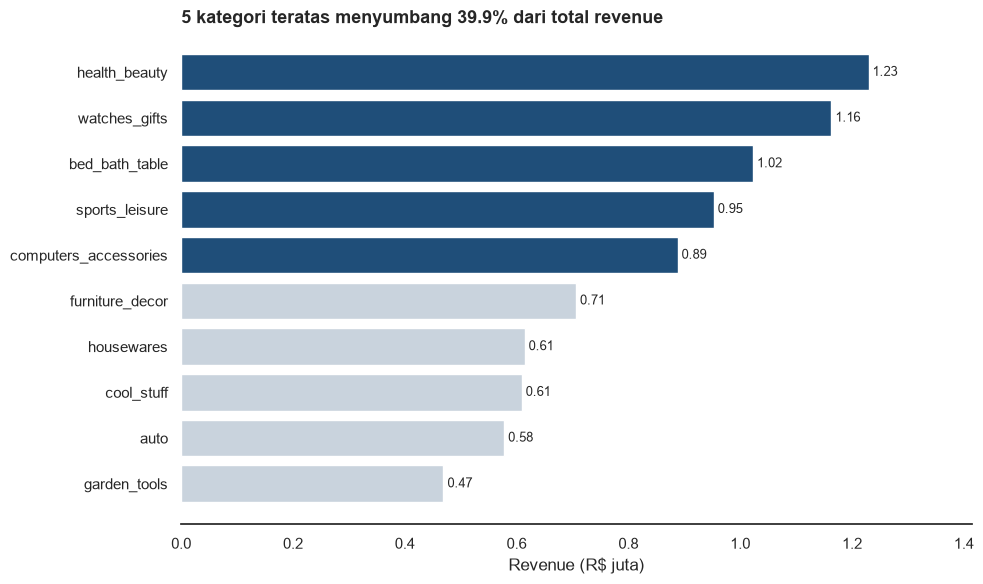

In [18]:
HIGHLIGHT, MUTED = "#1f4e79", "#c9d3dd"

top10 = category_revenue.head(10)
colors = [HIGHLIGHT if i < 5 else MUTED for i in range(len(top10))]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10["product_category_name_english"], top10["revenue"] / 1e6, color=colors)
ax.invert_yaxis()
for i, v in enumerate(top10["revenue"] / 1e6):
    ax.text(v, i, f" {v:,.2f}", va="center", fontsize=9)

ax.set_xlim(0, (top10["revenue"] / 1e6).max() * 1.15)
ax.set_title(f"5 kategori teratas menyumbang {top5_share:.1f}% dari total revenue", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Revenue (R$ juta)")
ax.set_ylabel("")
ax.tick_params(left=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 1:**

Kategori health_beauty ada di posisi pertama dengan revenue sekitar R$ 1,23 juta (9,3% dari total), disusul watches_gifts R$ 1,16 juta (8,8%) dan bed_bath_table R$ 1,02 juta (7,8%). Selisih nomor 1 dan 2 tidak jauh, hanya sekitar R$ 66 ribu. Menariknya, watches_gifts bisa di posisi kedua padahal jumlah pesanannya (5.489) jauh lebih sedikit dari bed_bath_table (9.267). Artinya nilai belanja per pesanannya lebih besar, sekitar R$ 212 dibanding sekitar R$ 110. Lima kategori teratas menyumbang 39,9% revenue dan sepuluh teratas sekitar 62,5%, jadi pendapatan cukup tersebar dan tidak bergantung pada satu kategori saja.

### Pertanyaan 2: Pelanggan dan waktu pengiriman per negara bagian

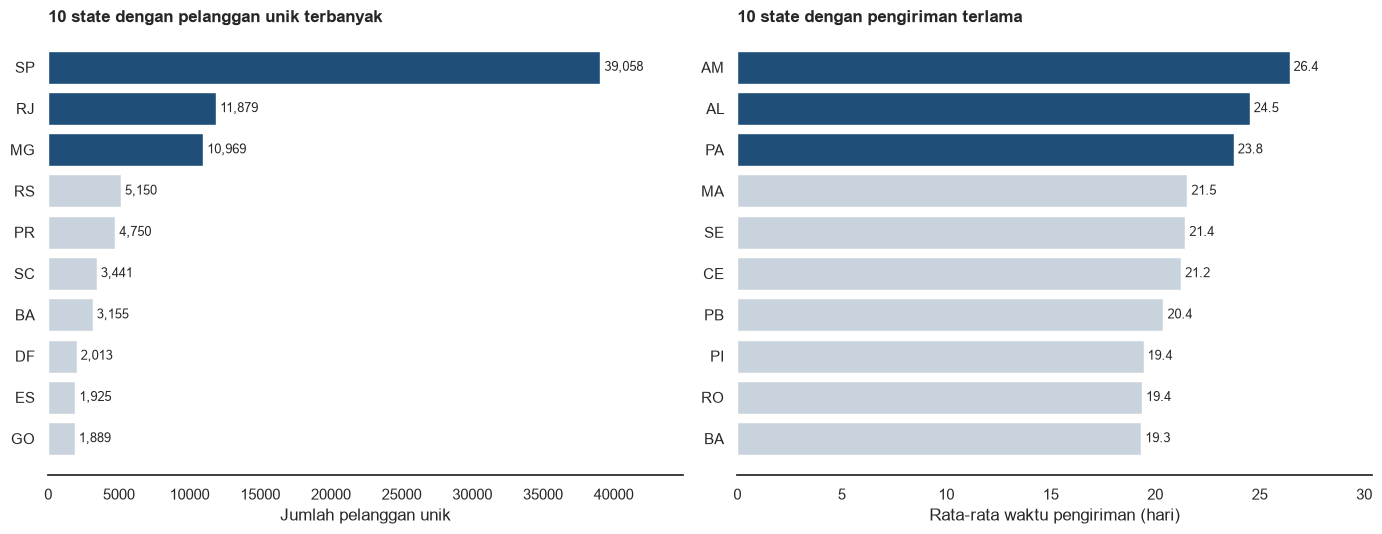

In [19]:
top_customers = state_summary.head(10)
top_slow = slowest_states.head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel kiri: jumlah pelanggan unik
colors_left = [HIGHLIGHT if i < 3 else MUTED for i in range(len(top_customers))]
axes[0].barh(top_customers["customer_state"], top_customers["customers"], color=colors_left)
axes[0].invert_yaxis()
for i, v in enumerate(top_customers["customers"]):
    axes[0].text(v, i, f" {v:,}", va="center", fontsize=9)
axes[0].set_xlim(0, top_customers["customers"].max() * 1.15)
axes[0].set_title("10 state dengan pelanggan unik terbanyak", loc="left", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Jumlah pelanggan unik")

# Panel kanan: rata-rata waktu pengiriman (state dengan >= 100 pesanan)
colors_right = [HIGHLIGHT if i < 3 else MUTED for i in range(len(top_slow))]
axes[1].barh(top_slow["customer_state"], top_slow["avg_delivery_days"], color=colors_right)
axes[1].invert_yaxis()
for i, v in enumerate(top_slow["avg_delivery_days"]):
    axes[1].text(v, i, f" {v:.1f}", va="center", fontsize=9)
axes[1].set_xlim(0, top_slow["avg_delivery_days"].max() * 1.15)
axes[1].set_title("10 state dengan pengiriman terlama", loc="left", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Rata-rata waktu pengiriman (hari)")

for ax in axes:
    ax.set_ylabel("")
    ax.tick_params(left=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

#### Analisis Lanjutan: Geospatial Analysis

**Tujuan:** melihat pola sebaran pelanggan dan waktu pengiriman secara geografis. Ukuran lingkaran menunjukkan jumlah pelanggan unik, sedangkan warna menunjukkan rata-rata waktu pengiriman (semakin gelap semakin lama). Titik koordinat tiap state adalah rata-rata koordinat pelanggan di state tersebut.

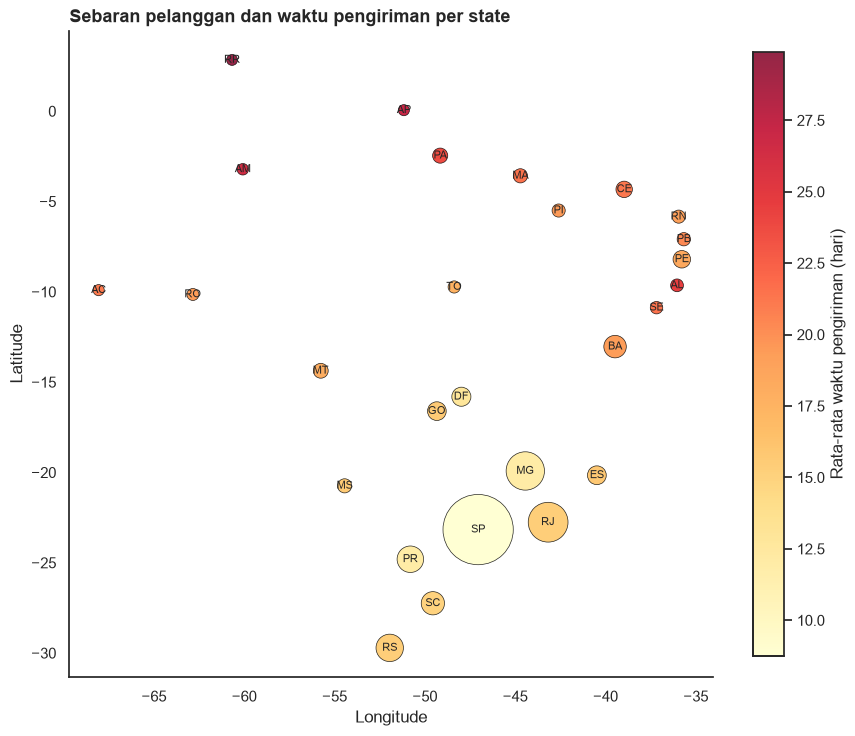

In [20]:
geo_plot = state_summary.dropna(subset=["lat", "lng"])

fig, ax = plt.subplots(figsize=(9, 9))
sizes = geo_plot["customers"] / geo_plot["customers"].max() * 2500 + 60
sc = ax.scatter(
    geo_plot["lng"], geo_plot["lat"], s=sizes, c=geo_plot["avg_delivery_days"],
    cmap="YlOrRd", edgecolor="black", linewidth=0.5, alpha=0.85,
)
for _, row in geo_plot.iterrows():
    ax.annotate(row["customer_state"], (row["lng"], row["lat"]), ha="center", va="center", fontsize=8)

cbar = plt.colorbar(sc, ax=ax, shrink=0.7)
cbar.set_label("Rata-rata waktu pengiriman (hari)")
ax.set_title("Sebaran pelanggan dan waktu pengiriman per state", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
sns.despine()
plt.tight_layout()
plt.show()

**Insight Pertanyaan 2:**

São Paulo (SP) punya pelanggan unik terbanyak, yaitu 39.058 atau sekitar 42% dari semua pelanggan, dan menyumbang sekitar 38% revenue. Bersama RJ dan MG, tiga state ini mencakup sekitar dua pertiga pelanggan. Pengiriman ke SP juga yang tercepat, rata-rata 8,7 hari. Sebaliknya, pengiriman terlama ada di Amazonas (AM) dengan 26,4 hari, hampir tiga kali lipat SP, diikuti AL (24,5 hari), PA (23,8 hari), MA (21,5 hari), dan SE (21,4 hari). Lima state terlama itu ada di wilayah utara dan timur laut Brasil yang jauh dari SP. Hal lain yang perlu dicatat, RJ dan RS pelanggannya banyak tapi pengirimannya sekitar 15 hari, hampir dua kali lipat SP. Kemungkinan penyebabnya penjual dan gudang menumpuk di SP, tapi ini baru dugaan dan belum diuji di analisis ini.

### Pertanyaan 3: Segmentasi pelanggan (RFM)

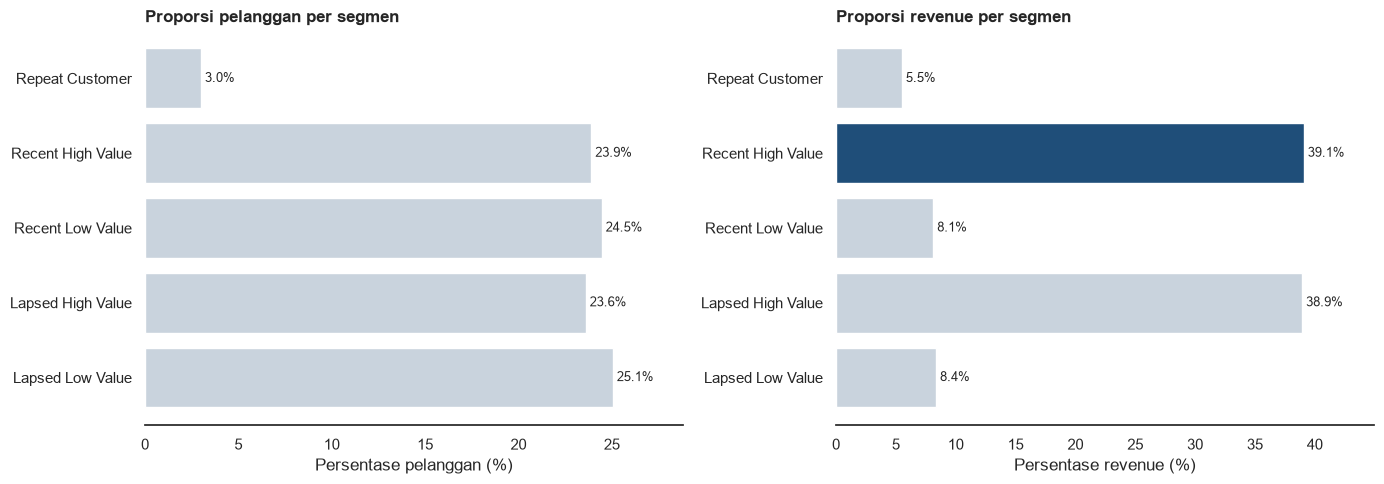

In [21]:
seg = rfm_summary.copy()
seg_colors = [HIGHLIGHT if v == seg["revenue_pct"].max() else MUTED for v in seg["revenue_pct"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(seg["segment"], seg["customers_pct"], color=MUTED)
axes[0].set_title("Proporsi pelanggan per segmen", loc="left", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Persentase pelanggan (%)")
axes[0].set_xlim(0, seg["customers_pct"].max() * 1.15)
for i, v in enumerate(seg["customers_pct"]):
    axes[0].text(v, i, f" {v:.1f}%", va="center", fontsize=9)

axes[1].barh(seg["segment"], seg["revenue_pct"], color=seg_colors)
axes[1].set_title("Proporsi revenue per segmen", loc="left", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Persentase revenue (%)")
axes[1].set_xlim(0, seg["revenue_pct"].max() * 1.15)
for i, v in enumerate(seg["revenue_pct"]):
    axes[1].text(v, i, f" {v:.1f}%", va="center", fontsize=9)

for ax in axes:
    ax.invert_yaxis()
    ax.set_ylabel("")
    ax.tick_params(left=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 3:**

Hanya 3,0% pelanggan (2.789 orang) yang berbelanja lebih dari sekali, jadi hampir semua pelanggan cuma membeli satu kali. Revenue terbesar datang dari dua segmen High Value: Recent High Value (23,9% pelanggan, 39,1% revenue) dan Lapsed High Value (23,6% pelanggan, 38,9% revenue). Digabung, kurang dari separuh pelanggan (47,5%) menyumbang sekitar 78% revenue, dengan rata-rata belanja sekitar R$ 232 per pelanggan. Dua segmen Low Value jumlahnya sekitar 49,5% pelanggan tapi hanya 16,5% revenue, dengan rata-rata belanja sekitar R$ 47. Pelanggan Repeat jumlahnya kecil tapi rata-rata belanjanya paling besar (R$ 260). Satu catatan: segmen “High” memang ditentukan dari skor belanja yang tinggi, jadi besarnya kontribusi mereka sebagian memang konsekuensi dari cara pengelompokan, bukan murni temuan.

## Conclusion

- **Kesimpulan Pertanyaan 1:** Kategori dengan revenue tertinggi pada Januari 2017 - Agustus 2018 adalah health_beauty (R$ 1,23 juta), diikuti watches_gifts (R$ 1,16 juta) dan bed_bath_table (R$ 1,02 juta). Lima kategori teratas menyumbang 39,9% dari total revenue R$ 13,18 juta, sehingga pendapatan cukup tersebar.
- **Kesimpulan Pertanyaan 2:** SP punya pelanggan unik terbanyak (39.058, sekitar 42%) dan pengiriman tercepat (8,7 hari). Pengiriman terlama ada di AM (26,4 hari), AL, PA, MA, dan SE, yang semuanya berada di wilayah utara dan timur laut. RJ dan RS juga cukup lambat, sekitar 15 hari, padahal pelanggannya banyak.
- **Kesimpulan Pertanyaan 3:** Hanya 3,0% pelanggan yang berbelanja lebih dari sekali. Dua segmen High Value (Recent dan Lapsed) menyumbang sekitar 78% revenue dari 47,5% pelanggan, sedangkan dua segmen Low Value hanya menyumbang sekitar 16,5% revenue.

## Rekomendasi (Action Item)

1. Prioritaskan stok dan promosi pada lima kategori teratas (health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories). Untuk watches_gifts, fokuskan pada nilai per pesanan yang tinggi, sedangkan bed_bath_table pada volume pesanan.
2. Perbaiki logistik di dua kelompok wilayah: state utara dan timur laut (AM, AL, PA, MA, SE) lewat mitra kurir lokal atau gudang regional, serta RJ dan RS yang pelanggannya banyak tapi pengirimannya sekitar 15 hari.
3. Buat program retensi: beri voucher pembelian kedua untuk segmen Recent High Value (22.247 pelanggan) supaya mereka kembali belanja, dan kampanye win-back untuk Lapsed High Value (21.970 pelanggan yang sudah rata-rata sekitar 362 hari tidak belanja). Untuk segmen Low Value, cukup promosi hemat biaya.